In [3]:
%pip install -q torch torchvision transformers pillow requests matplotlib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import requests
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel, AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

c:\Users\Charlotte\miniconda3\envs\astra_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 10743.00it/s]
Error while downloading from https://huggingface.co/api/resolve-cache/models/openai/clip-vit-base-patch32/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268/vocab.json?%2Fopenai%2Fclip-vit-base-patch32%2Fresolve%2F3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268%2Fvocab.json=&etag=%22182766ce89b439768edadda342519f33802f5364%22: The read operation timed out
Trying to resume download...


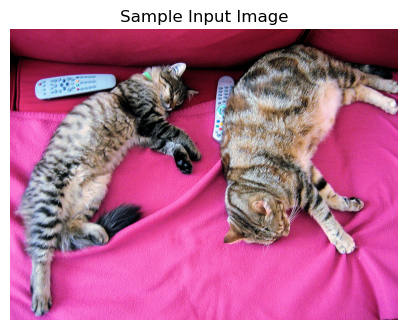

In [ ]:
model_id = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_id).to(device)
processor = CLIPProcessor.from_pretrained(model_id)

# sample image
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Sample Input Image")
plt.show()

In [6]:
labels = ["a photo of two cats sleeping", "a photo of more than one animal", "a photo of a couch", "a photo of a car"]

inputs = processor(
    text=labels, 
    images=image, 
    return_tensors="pt", 
    padding=True
).to(device)

# forward pass
with torch.no_grad():
    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image  # Image-to-text similarity score
    probs = logits_per_image.softmax(dim=1)      # Convert to probabilities

for label, prob in zip(labels, probs[0]):
    print(f"Label: '{label}' -> Probability: {prob.item():.4f}")

Label: 'a photo of two cats sleeping' -> Probability: 0.9952
Label: 'a photo of more than one animal' -> Probability: 0.0026
Label: 'a photo of a couch' -> Probability: 0.0021
Label: 'a photo of a car' -> Probability: 0.0000


In [7]:
class MultimodalTransformerClassifier(nn.Module):
    def __init__(self, vision_model_name="google/vit-base-patch16-224-in21k", text_model_name="bert-base-uncased", num_classes=2):
        super().__init__()
        
        self.vision_encoder = AutoModel.from_pretrained(vision_model_name)
        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        
        vision_dim = self.vision_encoder.config.hidden_size 
        text_dim = self.text_encoder.config.hidden_size     
        
        # multimodal fusion layer
        self.cross_attention = nn.MultiheadAttention(embed_dim=768, num_heads=8, batch_first=True)
        self.layer_norm = nn.LayerNorm(768)
        
        self.classifier = nn.Sequential(
            nn.Linear(768 * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, pixel_values, input_ids, attention_mask):
        # extract visual tokens
        vision_outputs = self.vision_encoder(pixel_values=pixel_values)
        visual_embeds = vision_outputs.last_hidden_state 
        
        # extract text tokens
        text_outputs = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        text_embeds = text_outputs.last_hidden_state
        
        # cross-attention
        attn_output, _ = self.cross_attention(query=text_embeds, key=visual_embeds, value=visual_embeds)
        fused_text = self.layer_norm(text_embeds + attn_output)
        
        # pool feature, cls token
        pooled_vision = visual_embeds[:, 0, :]
        pooled_text = fused_text[:, 0, :]
        
        multimodal_features = torch.cat((pooled_vision, pooled_text), dim=1)

        # final classification
        logits = self.classifier(multimodal_features)
        return logits

In [ ]:
from transformers import AutoImageProcessor, AutoTokenizer

image_processor = AutoImageProcessor.from_pretrained("google/vit-base-patch16-224-in21k")
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

custom_multimodal_model = MultimodalTransformerClassifier(num_classes=2).to(device)
optimizer = torch.optim.AdamW(custom_multimodal_model.parameters(), lr=1e-5)
criterion = nn.CrossEntropyLoss()

sample_text = ["This image shows two small cats.", "A bright red sports car."]
sample_image = image.convert("RGB").resize((224, 224))

image_inputs = image_processor(images=[sample_image, sample_image], return_tensors="pt").to(device)
text_inputs = tokenizer(sample_text, padding=True, return_tensors="pt").to(device)
targets = torch.tensor([0, 1]).to(device) # Mock targets

custom_multimodal_model.train()
optimizer.zero_grad()

logits = custom_multimodal_model(
    pixel_values=image_inputs.pixel_values,
    input_ids=text_inputs.input_ids,
    attention_mask=text_inputs.attention_mask
)

loss = criterion(logits, targets)
loss.backward()
optimizer.step()

print(f"Loss: {loss.item():.4f}")
print(f"Logits shape: {logits.shape}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6229.32it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Forward-Backward step completed successfully!
Loss: 0.6686
Logits shape: torch.Size([2, 2])
